M2 Mathématiques, Vision et Apprentissage
**Computational statistics** — Prof. Stéphanie Allassonnière
2026 – 2027 · **TP 1** Javier Molinero Araguas

# TP 1: Estimators – Simulation – Stochastic gradient descent

## Exercise 1: Comparing estimators in the uniform model

We consider the parametric family of uniform distributions $\{\mathcal{U}(\theta), \theta > 0\}$ on $\mathbb{R}$, where $\mathcal{U}(\theta)$ has the following density with respect to the Lebesgue measure:

$$
p_\theta(x) = \frac{1}{\theta}\,\mathbb{1}_{[0,\theta]}(x)\,.
$$

Let $X_1, \dots, X_n$ be an i.i.d. sample with density $p_\theta$. The goal of this exercise is to compare several estimators of $\theta$.

1. Compute $\mathbb{E}_\theta(X_1)$ and deduce an estimator $\hat\theta_1$ of $\theta$ by the method of moments.
2. Compute the quadratic risk of $\hat\theta_1$.
3. Compute the maximum likelihood estimator $\hat\theta_2$.
4. Compute the quadratic risk of $\hat\theta_2$.
5. Which estimator is preferable?

> **Remark.** The discrete version of this problem is the *German tank problem*. During World War II, Allied statisticians estimated the monthly production of German tanks from the serial numbers of captured or destroyed tanks, with estimators based on the largest observed serial number [RB47].

1. Compute $\mathbb{E}_\theta(X_1)$ and deduce an estimator $\hat\theta_1$ of $\theta$ by the method of moments.

$$
\mathbb{E}_\theta[X_1] = \int_0^\theta x \,\frac{1}{\theta}\, dx = \frac{1}{\theta}\left[\frac{x^2}{2}\right]_0^\theta = \frac{\theta}{2}.
$$
 
In the method of moments, we equate the theoretical moment with the empirical one. We therefore set
 
$$
\frac{\theta}{2} = \frac{1}{n}\sum_{i=1}^n X_i
\quad\Longrightarrow\quad
\boxed{\hat\theta_1 = \frac{2}{n}\sum_{i=1}^n X_i = 2\bar X.}
$$

2. Compute the quadratic risk of $\hat\theta_1$.

$$
R(\hat\theta_1) = \mathbb{E}\big[(\hat\theta_1 - \theta)^2\big].
$$
 
We first compute
 
$$
\mathbb{E}[\hat\theta_1] = \mathbb{E}\Big[\frac{2}{n}\sum_{i=1}^n X_i\Big] = \frac{2}{n}\sum_{i=1}^n \mathbb{E}[X_i] \overset{\text{i.i.d.}}{=} \frac{2}{n}\cdot n\cdot\frac{\theta}{2} = \theta
\quad\Longrightarrow\quad \hat\theta_1 \text{ is unbiased.}
$$
 
And now we see that
 
$$
\begin{aligned}
R(\hat\theta_1) &= \mathbb{E}[\hat\theta_1^2] - 2\,\mathbb{E}[\hat\theta_1\theta] + \theta^2 \\
&= \mathbb{E}[\hat\theta_1^2] - 2\theta\,\underbrace{\mathbb{E}[\hat\theta_1]}_{=\,\theta} + \theta^2 \\
&= \mathbb{E}[\hat\theta_1^2] - \theta^2 = \operatorname{Var}[\hat\theta_1].
\end{aligned}
$$
 
Since $\mathbb{E}[X_i^2] = \int_0^\theta \frac{x^2}{\theta}\,dx = \frac{\theta^2}{3}$, we have $\operatorname{Var}[X_i] = \frac{\theta^2}{3} - \frac{\theta^2}{4} = \frac{\theta^2}{12}$. By independence,
 
$$
\operatorname{Var}[\hat\theta_1] = \operatorname{Var}[2\bar X] = \frac{4}{n^2}\sum_{i=1}^n \operatorname{Var}[X_i] = \frac{4}{n}\cdot\frac{\theta^2}{12} = \frac{\theta^2}{3n}
\quad\Longrightarrow\quad
\boxed{R(\hat\theta_1) = \frac{\theta^2}{3n}.}
$$


3. Compute the maximum likelihood estimator $\hat\theta_2$.
We look for $\displaystyle\max_\theta\, p(x_1,\dots,x_n \mid \theta)$. The likelihood is
 
$$
\mathcal{L}(\theta) = p_\theta(x_1,\dots,x_n) \overset{\text{i.i.d.}}{=} \prod_{i=1}^n p_\theta(x_i) = \prod_{i=1}^n \frac{1}{\theta}\,\mathbb{1}_{[0,\theta]}(x_i) = \frac{1}{\theta^n}\,\mathbb{1}_{\{\theta \geq M_n\}}\,\mathbb{1}_{\{\min_i x_i \geq 0\}},
$$
 
where $M_n = \max\{x_1,\dots,x_n\}$.
 
The likelihood is $0$ for $\theta < M_n$, and for $\theta \geq M_n$ it equals $\theta^{-n}$, which is decreasing in $\theta$. It is therefore maximized at the smallest admissible value, $\theta = M_n$:
 
$$
\boxed{\hat\theta_2 = \max\{X_1,\dots,X_n\}.}
$$

4. Compute the quadratic risk of $\hat\theta_2$.


$$
R(\hat\theta_2) = \mathbb{E}\big[(\hat\theta_2 - \theta)^2\big].
$$
 
We compute the mean of the estimator by obtaining the CDF of $X_1$:
 
$$
F_\theta(x) = P(X_1 \leq x) = \int_0^x \frac{1}{\theta}\, dt = \frac{x}{\theta} \quad \text{for } 0 \le x \le \theta,
\qquad\text{so}\qquad
F_\theta(x) = \begin{cases} 0 & \text{if } x \leq 0, \\ x/\theta & \text{if } 0 < x \leq \theta, \\ 1 & \text{if } x > \theta. \end{cases}
$$
 
We know that, by independence, the CDF of the maximum of the sample is $P(M_n \le x) = P(X_1\le x,\dots,X_n \le x) = [F_\theta(x)]^n$, and its density function is
 
$$
f_\theta^{\max}(x) = n\,F_\theta(x)^{n-1}\,F_\theta'(x) = n\left(\frac{x}{\theta}\right)^{n-1}\frac{1}{\theta}\,\mathbb{1}_{[0,\theta]}(x)
\quad\Longrightarrow\quad
f_\theta^{\max}(x) = \frac{n\,x^{n-1}}{\theta^n}\,\mathbb{1}_{[0,\theta]}(x).
$$
 
Then
 
$$
\mathbb{E}[\hat\theta_2] = \int_0^\theta x\,\frac{n\,x^{n-1}}{\theta^n}\, dx = \left[\frac{n\,x^{n+1}}{(n+1)\,\theta^n}\right]_0^\theta = \frac{n}{n+1}\,\theta.
$$
 
We know that the risk can be decomposed into variance and squared bias:
 
$$
R(\hat\theta_2) = \operatorname{Var}[\hat\theta_2] + \operatorname{Bias}^2[\hat\theta_2].
$$
 
On one side,
 
$$
\operatorname{Bias}^2[\hat\theta_2] = \left(\theta - \frac{n}{n+1}\,\theta\right)^2 = \frac{\theta^2}{(n+1)^2}.
$$
 
On the other side, $\operatorname{Var}[\hat\theta_2] = \mathbb{E}[\hat\theta_2^2] - \mathbb{E}^2[\hat\theta_2]$. We compute
 
$$
\mathbb{E}[\hat\theta_2^2] = \int_0^\theta x^2\,\frac{n\,x^{n-1}}{\theta^n}\, dx = \frac{n}{\theta^n}\left[\frac{x^{n+2}}{n+2}\right]_0^\theta = \frac{n\,\theta^2}{n+2},
$$
 
so
 
$$
\operatorname{Var}[\hat\theta_2] = \frac{n\theta^2}{n+2} - \frac{n^2\theta^2}{(n+1)^2}
= \frac{(n+1)^2\, n\theta^2 - n^2(n+2)\,\theta^2}{(n+2)(n+1)^2}
= \frac{n\,\theta^2}{(n+1)^2(n+2)},
$$
 
since $(n+1)^2 - n(n+2) = 1$. Then,
 
$$
R(\hat\theta_2) = \frac{n\theta^2}{(n+1)^2(n+2)} + \frac{\theta^2}{(n+1)^2}
= \frac{(2n+2)\,\theta^2}{(n+1)^2(n+2)}
\quad\Longrightarrow\quad
\boxed{R(\hat\theta_2) = \frac{2\theta^2}{(n+1)(n+2)}.}
$$

5. Which estimator is preferable?
   
We compare both estimators' risks:
 
$$
\frac{\theta^2}{3n} \geq \frac{2\theta^2}{(n+1)(n+2)}
\iff (n+1)(n+2) \geq 6n
\iff n^2 - 3n + 2 \geq 0
\iff (n-1)(n-2) \geq 0,
$$
 
which holds for every integer $n \geq 1$. Hence $R(\hat\theta_1) \geq R(\hat\theta_2)$ for all $n \geq 1$.
 
Although $\hat\theta_1$ is unbiased while $\hat\theta_2$ is not, the risk of $\hat\theta_2$ converges to $0$ much faster (at a rate of $1/n^2$). Moreover, the variance of $\hat\theta_2$ also decreases at a rate of $1/n^2$, while $\operatorname{Var}[\hat\theta_1]$ does so at $1/n$.
 
We thus choose $\hat\theta_2$ as the better estimator, and we could make it unbiased by multiplying it by $\frac{n+1}{n}$.

## Exercise 2: Box–Muller and Marsaglia–Bray algorithms
 
Let $R$ be a random variable with Rayleigh distribution with parameter 1, and $\Theta$ a random variable with uniform distribution on $[0, 2\pi]$, independent of $R$. The density of $R$ with respect to the Lebesgue measure is
 
$$
\forall r \in \mathbb{R}, \qquad f_R(r) = r \exp\left(-\frac{r^2}{2}\right) \mathbb{1}_{\mathbb{R}^+}(r)\,.
$$
 
1. Define $X$ and $Y$ by
   $$
   X = R\cos(\Theta) \qquad \text{and} \qquad Y = R\sin(\Theta)\,.
   $$
   **Prove that $X$ and $Y$ are independent with distribution $\mathcal{N}(0, 1)$.**
 
   By hypothesis, we know $R$ and $\Theta$ are independent, so
   
   $$
   f_{R,\Theta}(r,\theta) = f_R(r)\,f_\Theta(\theta) = r\exp\left(-\frac{r^2}{2}\right)\mathbb{1}_{\mathbb{R}^+}(r)\,\frac{1}{2\pi}\,\mathbb{1}_{[0,2\pi)}(\theta).
   $$
   
   Now, we can apply the Theorem of Transformation of Random Variables. Our transformation is given by $\varphi(r,\theta) = (r\cos\theta,\ r\sin\theta)$ and the domain goes from
   
   $$
   (0,\infty)\times(0,2\pi) \longrightarrow \mathbb{R}^2 \setminus \{(x,0) : x \geq 0\} \quad \text{since } \theta \in (0,2\pi).
   $$
   
   We invert $\varphi$:
   
   $$
   \begin{cases} x = r\cos\theta \\ y = r\sin\theta \end{cases}
   \quad\rightsquigarrow\quad
   \begin{cases} r = \sqrt{x^2+y^2} \\ \theta = \arctan(y/x) \end{cases}
   $$
   
   We aim to compute $|J_{\varphi^{-1}}|$, but we'll do
   
   $$
   |J_\varphi| = \begin{vmatrix} \cos\theta & -r\sin\theta \\ \sin\theta & r\cos\theta \end{vmatrix} = r
   \quad\Longrightarrow\quad
   |J_{\varphi^{-1}}| = \frac{1}{r} = \frac{1}{\sqrt{x^2+y^2}}.
   $$
   
   And applying the theorem we get:
   
   $$
   f_{X,Y}(x,y) = \underbrace{\sqrt{x^2+y^2}\,\exp\left\{-\frac{x^2+y^2}{2}\right\}\frac{1}{2\pi}}_{f_{R,\Theta}(\varphi^{-1}(x,y))}\cdot\underbrace{\frac{1}{\sqrt{x^2+y^2}}}_{|J_{\varphi^{-1}}|}\ \underbrace{\mathbb{1}_{\mathbb{R}^2\setminus\{(x,0):\,x\geq 0\}}(x,y)}_{\text{new domain}}
   $$
   
   $$
   = \underbrace{\frac{1}{\sqrt{2\pi}}\exp\left\{-\frac{x^2}{2}\right\}}_{\mathcal{N}(0,1)}\cdot\underbrace{\frac{1}{\sqrt{2\pi}}\exp\left\{-\frac{y^2}{2}\right\}}_{\mathcal{N}(0,1)} = f_X(x)\,f_Y(y)
   \quad\Longrightarrow\quad \text{they are independent and both with distribution $\mathcal{N}(0,1)$.}
   $$
   
   \* The indicator function can be ignored since $\{(x,0) : x \geq 0\}$ has null measure, and thus it does not affect the density.

   **Algorithm 1: Marsaglia–Bray algorithm**
   
   ```
   1  V1 = 1, V2 = 1;
   2  while V1² + V2² > 1 do
   3      Sample independent U1, U2 with distribution U([0, 1]);
   4      Set V1 = 2·U1 − 1 and V2 = 2·U2 − 1;
   5  end
   6  Set S = sqrt(−2 log(V1² + V2²));
   7  Set X = S · V1 / sqrt(V1² + V2²)  and  Y = S · V2 / sqrt(V1² + V2²);
   8  return (X, Y).
   ```
 
**2. Write an algorithm that samples independent $\mathcal{N}(0, 1)$ variables from independent uniform variables (Box–Muller algorithm).**

   **Algorithm 2: Box-Muller algorithm**
   ```
   1. sample independent u1, u2 with distribution U([0,1])
   2. theta = 2*pi*u2 # general formula to rescale a uniform (a,b): a+(b-a)*u
   3. r = sqrt(-2 * ln(1-u1)) #see the demonstration below (*)
   4. x = r*cos(theta)
   5. y = r*sin(theta)
   6. return (x,y)
   ```
   (*) 
   $$
   U \longrightarrow R
   \qquad
   \begin{cases}
   f_U = \mathbb{1}_{(0,1)}(u) \\[1mm]
   f_R = r\exp\left\{-\dfrac{r^2}{2}\right\}\mathbb{1}_{\mathbb{R}^+}(r)
   \end{cases}
   $$
   
   $$
   F_R(t) = \int_0^t r\exp\left\{-\frac{r^2}{2}\right\}dr = \left[-\exp\left\{-\frac{r^2}{2}\right\}\right]_0^t = 1 - e^{-\frac{t^2}{2}}
   $$
   
   Similarly, $F_R(r) = P(R \leq r) = 1 - e^{-r^2/2}$.
   
   Let's suppose this CDF generated a uniform value $u_1$ and then we'll apply the inversion method:
   
   $$
   u_1 = 1 - e^{-r^2/2}
   \quad\Longrightarrow\quad
   r = \sqrt{-2\log(1-u_1)}
   $$
   
   (we discard the $(-)$ case because it's outside the domain)


3. **Consider the Marsaglia–Bray algorithm given above (Algorithm 1).**
- **a)** What is the distribution of $(V_1, V_2)$ at the end of the "while" loop?


Since $U_1 \sim \mathcal{U}(0,1)$; $U_2 \sim \mathcal{U}(0,1)$ and
 
$$
\begin{cases}
V_1 = 2U_1 - 1 = -1 + \big(1-(-1)\big)\,U_1 \ \Longrightarrow\ V_1 \sim \mathcal{U}(-1,1) \\[1mm]
V_2 = 2U_2 - 1 = -1 + \big(1-(-1)\big)\,U_2 \ \Longrightarrow\ V_2 \sim \mathcal{U}(-1,1)
\end{cases}
$$
 
They're both independent and equally distributed, so
 
$$
f_{V_1,V_2}(v_1,v_2) = \frac{1}{4}\,\mathbb{1}_{[-1,1]^2}(v_1,v_2).
$$
 
The new distribution $(V_1^*, V_2^*)$ can be thought as *"Which is the probability of a point being in a subset of the unit disk, given that it was already in the unit disk?"* So, denoting $C$ = unit disk and $A \subset C$:
 
$$
P\big((V_1^*,V_2^*) \in A\big) = P\big((V_1,V_2) \in A \mid (V_1,V_2) \in C\big) = \frac{P\big((V_1,V_2) \in A \cap C\big)}{P\big((V_1,V_2) \in C\big)}
$$
 
Since $p = P(V_1,V_2 \in C) = \pi/4$ (see the calculations in the b question) and that $P(V_1,V_2 \in A) = \iint_A \frac{1}{4}\,dv_1\,dv_2$, so
 
$$
P\big((V_1^*,V_2^*) \in A\big) = \frac{\iint_A \frac{1}{4}\,dv_1\,dv_2}{\pi/4} = \boxed{\iint_A \frac{1}{\pi}\,dv_1\,dv_2}
$$
 
This is
 
$$
f_{V_1^*V_2^*}(v_1,v_2) = \frac{1}{\pi}\,\mathbb{1}_C(v_1,v_2).
$$
 
So $(V_1^*, V_2^*)$ are distributed as a uniform over the unit disk.
 
  
- **b)** What is the expected number of passes through the "while" loop?

   
We define $W = V_1^2 + V_2^2$ where $V_1, V_2$ i.i.d. $\mathcal{U}(-1,1)$. We want to compute
 
$$
p = P(W < 1) = 1 - P(W \geq 1) \equiv \text{a given try is accepted.}
$$
 
Since they're independent,
 
$$
f_{V_1,V_2}(v_1,v_2) = \frac{1}{2}\,\mathbb{1}_{[-1,1]}(v_1)\,\frac{1}{2}\,\mathbb{1}_{[-1,1]}(v_2) = \frac{1}{4}\,\mathbb{1}_{[-1,1]^2}(v_1,v_2).
$$
 
$$
p = \int_0^{2\pi}\!\!\int_0^1 \frac{1}{4}\,r\,dr\,d\theta = \int_0^{2\pi} \frac{1}{4}\cdot\frac{1}{2}\,d\theta = \frac{\pi}{4} \approx 0.7854
$$
 
where we do a coordinates change to polar: $\begin{bmatrix} v_1 = r\cos\theta \\ v_2 = r\sin\theta \end{bmatrix}$, $|\det| = r$.
 
On average, about 78.54\% of the points are accepted. To answer the question, we define a model
 
$$
N \sim \text{Geom}(p) \equiv \text{N° of iterations inside while}
$$
 
$$
P(N = k) = (1-p)^{k-1}\cdot p
$$
 
$$
\rightsquigarrow\ \mathbb{E}[N] = \sum_{k=1}^{\infty} k\,(1-p)^{k-1}\,p = p\sum_{k=1}^{\infty} k\,(1-p)^{k-1}
$$
 
We do
 
$$
\sum_{k=0}^{\infty} \underbrace{(1-p)^k}_{q^k} = \frac{1}{1-\underbrace{(1-p)}_{q}} = \frac{1}{1-q} \ \overset{\partial/\partial q}{\rightsquigarrow}\ \sum_{k=1}^{\infty} k\,q^{k-1} = \frac{1}{(1-q)^2}
$$
 
So then
 
$$
\mathbb{E}[N] = p\,\frac{1}{(1-q)^2} = \frac{p}{p^2} = \frac{1}{p} \approx 1.27
$$
 
We'll approximately need 1.27 tries in the while loop.

- **c)** Set
  $$
  T_1 = \frac{V_1}{\sqrt{V_1^2 + V_2^2}} \qquad \text{and} \qquad V = V_1^2 + V_2^2\,.
  $$
  **Show that $T_1$ and $V$ are independent, that $V \sim \mathcal{U}([0, 1])$, and that $T_1$ has the same distribution as $\cos(\Theta)$ with $\Theta \sim \mathcal{U}([0, 2\pi])$.**
$$
T_1 = \underbrace{\frac{V_1}{\sqrt{V_1^2+V_2^2}}}_{\text{cosine of the angle}}
\qquad\qquad
V = \underbrace{V_1^2+V_2^2}_{\text{squared distance to the origin}}
$$
 
**$T_1$ and $V$ are independent**
 
$$
(V_1, V_2) \sim \mathcal{U}(C) \ \Longrightarrow\ f_{V_1,V_2}(v_1,v_2) = \frac{1}{\pi}\,\mathbb{1}_C
$$
 
The transformation $T_1, V$ is not bijective, so we can't apply the variable transformation theorem. We should thus try a different strategy:
 
Let's define
 
$$
\varphi:\quad
\begin{cases}
V_1 = r\cos\theta = \sqrt{V}\cos\theta \\
V_2 = r\sin\theta = \sqrt{V}\sin\theta
\end{cases}
$$
 
which is bijective with domain
 
$$
(0,1)\times(0,2\pi) \ \overset{\varphi}{\longrightarrow}\ C \setminus \{(x,0) : x \geq 0\}
$$
 
(the theorem sets as a condition an open set).
 
Applying the theorem as we did in 2.1 we get
 
$$
\varphi^{-1}:\quad
\begin{cases}
V = V_1^2 + V_2^2 \\
\theta = \arctan(V_2/V_1)
\end{cases}
\quad\rightsquigarrow\quad
J_{\varphi^{-1}} =
\begin{pmatrix}
2V_1 & \dfrac{1}{1+\left(\frac{V_2}{V_1}\right)^2}\cdot\left(-\dfrac{V_2}{V_1^2}\right) \\[4mm]
2V_2 & \dfrac{1}{1+\left(\frac{V_2}{V_1}\right)^2}\cdot\dfrac{1}{V_1}
\end{pmatrix}
$$
 
$$
|J_{\varphi^{-1}}| = 2 \ \Longrightarrow\ |J_\varphi| = \frac{1}{2}
$$
 
Then:
 
$$
\begin{aligned}
f_{V,\theta} &= \frac{1}{\pi}\cdot\frac{1}{2}\cdot\mathbb{1}_{(0,1)\times(0,2\pi)}(v,\theta) \\
&= \frac{1}{2\pi}\,\mathbb{1}_{(0,2\pi)}(\theta)\cdot\mathbb{1}_{(0,1)}(v) \\
&= \underbrace{f_\theta(\theta)}_{\sim\,\mathcal{U}(0,2\pi)}\cdot\underbrace{f_V(v)}_{\sim\,\mathcal{U}(0,1)} \ \longrightarrow\ V \text{ and } \theta \text{ are independent.}
\end{aligned}
$$
 
And, since
 
$$
T_1 = \frac{V_1}{\sqrt{V}} = \frac{\sqrt{V}\cos\theta}{\sqrt{V}} = \cos\theta
$$
 
we conclude that $T_1$ and $V$ are also independent, since $T_1 = \cos\theta$ only depends on $\theta$. Moreover, $V \sim \mathcal{U}([0,1])$, and since $\theta \sim \mathcal{U}(0,2\pi)$, $T_1$ has the same distribution as $\cos(\Theta)$ with $\Theta \sim \mathcal{U}([0,2\pi])$.
  
- **d)** **What is the distribution of the output $(X, Y)$?**

Let's see the distribution of $S$:
 
$$
\varphi(V) = S = \sqrt{-2\log V} \qquad \text{dom}: (0,1) \overset{\varphi}{\longrightarrow} (0,\infty) \ (\text{open set})
$$
 
$$
\varphi^{-1}(s) = \exp\left\{-\frac{s^2}{2}\right\} \ \Longrightarrow\ |J_{\varphi^{-1}}(s)| = s\,e^{-s^2/2}
$$
 
$$
f_V(v) = \mathbb{1}_{(0,1)}(v) \ \overset{\text{Theorem of transformation}}{\Longrightarrow}\ f_S(s) = s\,e^{-s^2/2}\,\mathbb{1}_{\mathbb{R}^+}(s) \sim \mathcal{R}a(1)
$$
 
Now, since in 3.c we wrote $V_1 = \sqrt{V}\cos\theta$ and $V_2 = \sqrt{V}\sin\theta$, the output of the algorithm is
 
$$
X = S\,\frac{V_1}{\sqrt{V}} = S\cos\theta \qquad\text{and}\qquad Y = S\,\frac{V_2}{\sqrt{V}} = S\sin\theta
$$
 
And so, since
 
$$
\begin{cases}
S \sim \mathcal{R}a(1) \\
\theta \sim \mathcal{U}(0,2\pi) \\
S \text{ and } \theta \text{ are independent, since } S \text{ only depends on } V \text{ and we saw in 3.c that } V \text{ and } \theta \text{ are independent}
\end{cases}
$$
 
we know from question 2.1 that $X$ and $Y$ are independent and both distributed as $\mathcal{N}(0,1)$.

## Exercise 3: Learning a linear classifier, [Bot91, BCN18]

Inputs $x \in \mathbb{R}^d$ and labels $y \in \{-1, +1\}$ follow an unknown joint distribution $\mathbb{P}$. If $\mathbb{P}$ were known, the Bayes rule based on $\mathbb{P}(y \mid x)$ would be optimal. In practice we only observe $n$ labeled samples $(x_1, y_1), \dots, (x_n, y_n)$, and we want a classifier that also performs well on new data.

We only consider linear classifiers, of the form

$$
h(x; w, \tau) = \langle w, x\rangle + \tau,
$$

where $w \in \mathbb{R}^d$ is a weight vector and $\tau \in \mathbb{R}$ a bias. The classifier separates the two classes by a hyperplane. The bias can be adjusted to favor either precision ($\mathbb{P}[y = 1 \mid h(x) > 0]$) or recall ($\mathbb{P}[h(x) > 0 \mid y = 1]$).

The predicted label is $\operatorname{sign}(h(x))$. The empirical classification error is piecewise constant in $(w, \tau)$, so gradient methods cannot minimize it; it is replaced by a continuous loss.

### The Adaline model

The Adaline (adaptive linear neuron) of Widrow and Hoff (1960) uses this linear function. We write $\bar x = (x, 1) \in \mathbb{R}^{d+1}$ and $\bar w = (w, \tau)$, so that $h(x; w, \tau) = \langle \bar w, \bar x\rangle$, and minimizes the mean squared error

$$
L(\bar w) = \mathbb{E}_{(x,y)\sim\mathbb{P}}\left[(y - \langle \bar w, \bar x\rangle)^2\right].
$$

Since $\mathbb{P}$ is unknown, $L$ is replaced by the empirical risk

$$
\boxed{L_n(\bar w) = \frac{1}{n}\sum_{i=1}^{n} (y_i - \langle \bar w, \bar x_i\rangle)^2.}
$$

Its minimizer $\widehat{\bar w} = (\hat w, \hat\tau)$ estimates the minimizer $\bar w_L$ of $L$.

**Notation.** In the synthetic experiments below, the labels are generated by a "true" hyperplane $(w_\star, \tau_\star)$. In general, $\bar w_L$ differs from $(w_\star, \tau_\star)$.

1. **(Python)** **Generate observations $(x_i, y_i)_{1 \leqslant i \leqslant n}$: sample points $x_i$ in $\mathbb{R}^2$ (for instance $x_i \sim \mathcal{N}(0, I_2)$), and choose a normal vector $w_\star$ and a bias $\tau_\star$ that define the separating hyperplane. The label is $y_i = \operatorname{sign}(\langle w_\star, x_i\rangle + \tau_\star)$.**

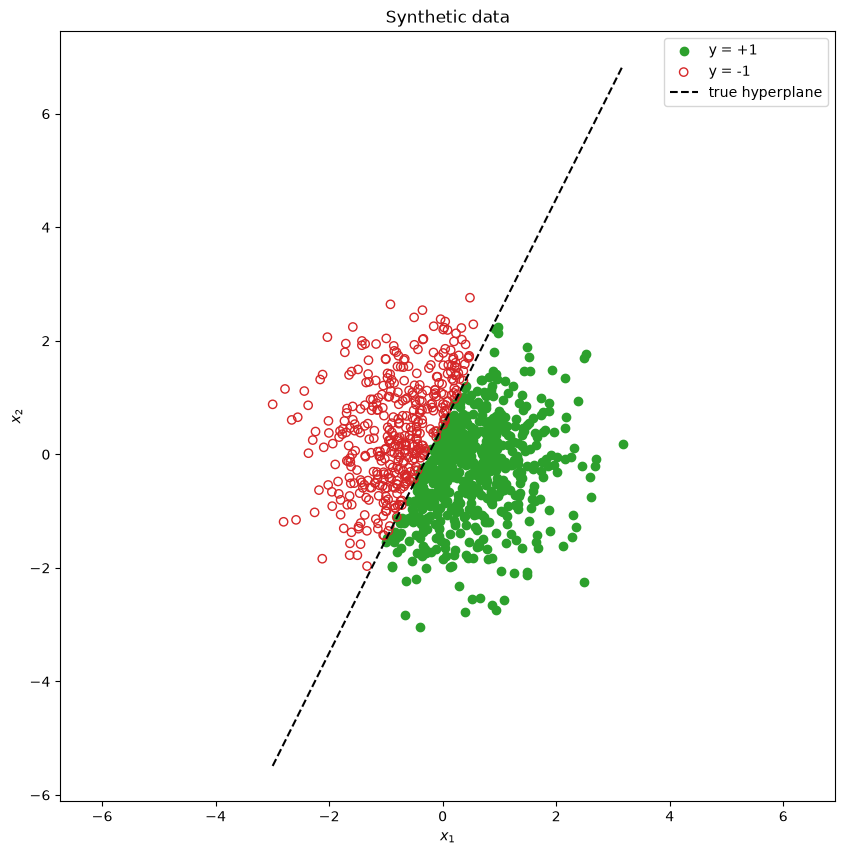

In [1]:
import numpy as np, matplotlib.pyplot as plt

np.random.seed(0)

n=1000
d=2

# the true hyperplane
w_star = np.array([2.0, -1.0])
tau_star = 0.5

x = np.random.normal(0,1, size=(n,d))
y = np.sign((np.dot(x, w_star) + tau_star))


plt.figure(figsize=(10,10))
plt.scatter(x[y == 1, 0], x[y == 1, 1], c="tab:green", marker="o", label="y = +1")
plt.scatter(x[y == -1, 0], x[y == -1, 1], edgecolors="tab:red", marker="o",
            facecolors="none", label="y = -1")


x1 = np.linspace(x[:, 0].min(), x[:, 0].max(), 100)
plt.plot(x1, -(w_star[0] * x1 + tau_star) / w_star[1], "k--", label="true hyperplane")

plt.xlabel("$x_1$"); plt.ylabel("$x_2$")
plt.axis("equal"); plt.legend()
plt.title("Synthetic data")
plt.show()


**2. Write a stochastic gradient descent (SGD) algorithm that minimizes $L_n$.**

We compute the "backpropagation equations":
 
$$
L_i(\bar w) = \big(y_i - w^\top x_i - \tau\big)^2
$$
 
$$
\frac{\partial L_i}{\partial w} = -2\,x_i\,\big(y_i - w^\top x_i - \tau\big)
$$
 
$$
\frac{\partial L_i}{\partial \tau} = -2\,\big(y_i - w^\top x_i - \tau\big)
$$
 
**Algorithm: SGD for Adaline model**
 
```
batch_size = b
w = w_initial
tau = tau_initial
learning_rate = eta
iterations = n_iterations

for k in iterations:
    idx = random.sample(range(n), size=batch_size)

    # Forward
    loss = 1/batch_size * sum( (y_i - w^T*x_i - tau)^2  for i in idx )

    w   = w   - eta * 1/batch_size * sum( dL_i/dw    for i in idx )
    tau = tau - eta * 1/batch_size * sum( dL_i/dtau  for i in idx )

return w, tau
```

**3. (Python) Implement and test the algorithm on the observations of question 1. Plot $L_n(\bar w_k)$ along the iterations, and the estimated decision boundary. What is the estimated vector $\widehat{\bar w}$? Compare the direction of $\hat w$ with that of $w_\star$ (angle or cosine). Why has the norm of $\hat w$ no reason to match $\|w_\star\|$?**




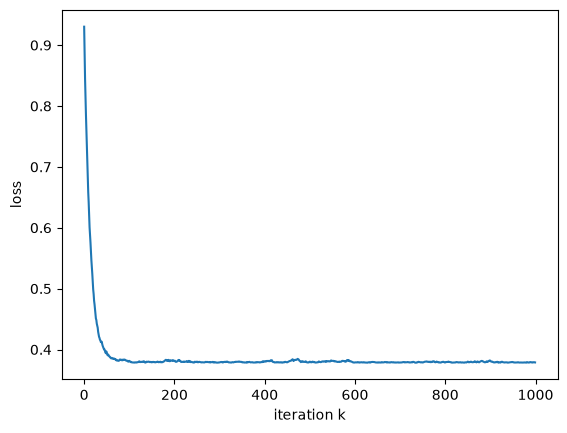

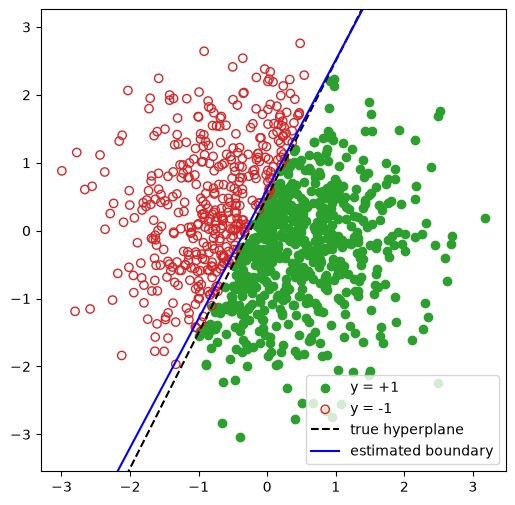

w_hat = [ 0.68214674 -0.35826559], tau_hat = 0.2187
cos(w_hat, w_star) = 0.9998  (angle = 1.14°)
||w_hat|| = 0.7705   ||w_star|| = 2.2361


In [2]:
def full_loss(x, y, w, tau):
    """Empirical risk L_n(w_bar) on the whole data set."""
    return np.mean((y - x @ w - tau) ** 2)

def train_adaline(x, y, w=None, tau=0.0, batch_size=16, learning_rate=0.02, iterations=1000, plot=True):
    n, d = x.shape
    if w is None:
        w = np.zeros(d)
    
    train_loss = np.zeros(iterations)
    
    for k in range(iterations):
        idx = np.random.choice(n, batch_size, replace=False)
    
        r = y[idx] - x[idx] @ w - tau                            
        grad_w = (1 / batch_size) * np.sum(-2 * x[idx] * r[:, None], axis=0)
        grad_tau = (1 / batch_size) * np.sum(-2 * r)
    
        w = w - learning_rate * grad_w
        tau = tau - learning_rate * grad_tau
    
        train_loss[k] = full_loss(x, y, w, tau)

    if plot==True:

        # L_n along the iterations
        plt.figure()
        plt.plot(train_loss)
        plt.xlabel("iteration k"); plt.ylabel("loss")
        plt.show()

        # data + true and estimated boundaries
        plt.figure(figsize=(6, 6))
        plt.scatter(x[y == 1, 0], x[y == 1, 1], c="tab:green", marker="o", label="y = +1")
        plt.scatter(x[y == -1, 0], x[y == -1, 1], facecolors="none", edgecolors="tab:red", label="y = -1")
        x1 = np.linspace(x[:, 0].min(), x[:, 0].max(), 100)
        plt.plot(x1, -(w_star[0]*x1 + tau_star)/w_star[1], "k--", label="true hyperplane")
        plt.plot(x1, -(w[0]*x1 + tau)/w[1], "b-", label="estimated boundary")
        plt.ylim(x[:, 1].min() - 0.5, x[:, 1].max() + 0.5)
        plt.legend(); plt.show()

    return w, tau

w_hat, tau_hat = train_adaline(x, y)

cos = w_hat @ w_star / (np.linalg.norm(w_hat) * np.linalg.norm(w_star))
angle = np.degrees(np.arccos(cos))

print(f"w_hat = {w_hat}, tau_hat = {tau_hat:.4f}")
print(f"cos(w_hat, w_star) = {cos:.4f}  (angle = {angle:.2f}°)")
print(f"||w_hat|| = {np.linalg.norm(w_hat):.4f}   ||w_star|| = {np.linalg.norm(w_star):.4f}")




The vector $\hat{\bar w} = (\hat w, \hat\tau) = (0.682, -0.358, 0.219)$ is the vector of parameters learnt by the model after all the SGD iterations.

Since the cosine between $\hat w$ and $w_\star$ is 0.9998 (angle of 1.14°), the direction is almost the same as the one given by the original vector $w_\star = (2,-1)$. The norm, on its side, is not an indicator of the quality of the model.

The classifier only depends on the hyperplane $\{\langle w, x\rangle + \tau = 0\}$, which is invariant under $(w,\tau) \mapsto c\,(w,\tau)$ for any $c>0$. So $(w_\star, \tau_\star)$ is only defined up to a positive factor, and $\|w_\star\|$ is an arbitrary choice.

Adaline does not look for that hyperplane directly. It solves a least-squares regression of the labels $y_i \in \{-1,+1\}$ on $\bar x_i$, so the scale of $\hat w$ is set by the targets $\pm 1$. Then $\langle \hat w, x_i\rangle + \hat\tau$ has to stay of order 1, whatever the scale of $w_\star$.


4. **(Python)** Add Gaussian noise to the features, $\tilde x_i = x_i + \varepsilon_i$ with $\varepsilon_i \sim \mathcal{N}(0, s^2 I_2)$, the labels being computed from the noiseless $x_i$, and run the optimization again. Compare with the result of question 3.

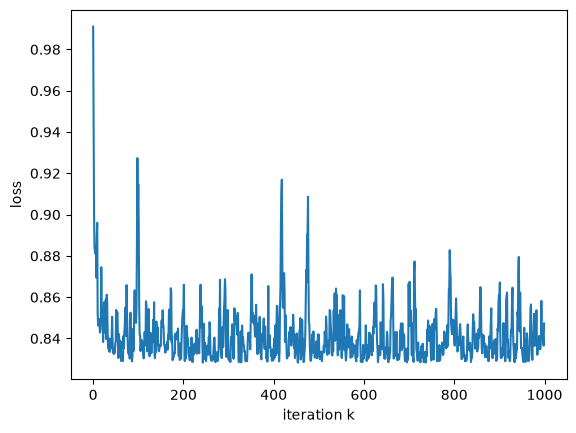

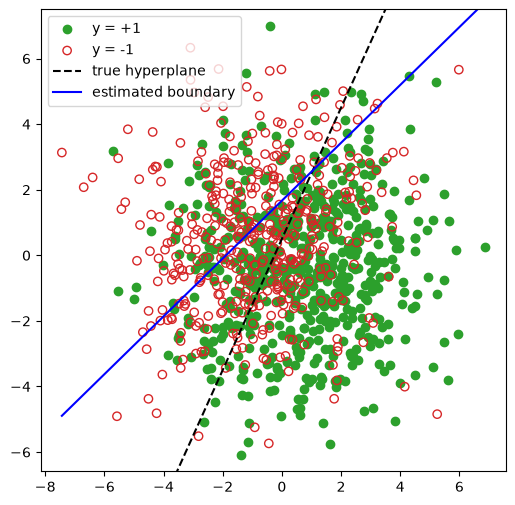

w_noisy = [ 0.12686374 -0.14381175], tau_noisy = 0.2396
cos(w_noisy, w_star) = 0.9271  (angle = 22.02°)
||w_noisy|| = 0.1918   ||w_hat|| = 0.7705
accuracy: clean = 0.977   noisy = 0.663
L_n: clean = 0.379   noisy = 0.847


In [3]:
s=2
eps = np.random.normal(0, s, size=(n,d))
noisy_x = x + eps
w_noisy, tau_noisy = train_adaline(noisy_x, y)

cos_noisy = w_noisy @ w_star / (np.linalg.norm(w_noisy) * np.linalg.norm(w_star))
angle_noisy = np.degrees(np.arccos(cos_noisy))
acc_clean = np.mean(np.sign(x @ w_hat + tau_hat) == y)
acc_noisy = np.mean(np.sign(noisy_x @ w_noisy + tau_noisy) == y)

print(f"w_noisy = {w_noisy}, tau_noisy = {tau_noisy:.4f}")
print(f"cos(w_noisy, w_star) = {cos_noisy:.4f}  (angle = {angle_noisy:.2f}°)")
print(f"||w_noisy|| = {np.linalg.norm(w_noisy):.4f}   ||w_hat|| = {np.linalg.norm(w_hat):.4f}")
print(f"accuracy: clean = {acc_clean:.3f}   noisy = {acc_noisy:.3f}")
print(f"L_n: clean = {full_loss(x, y, w_hat, tau_hat):.3f}   noisy = {full_loss(noisy_x, y, w_noisy, tau_noisy):.3f}")

With noise $s=2$ the classes overlap in the observed features $\tilde x_i$, so the data are no longer linearly separable and no hyperplane can classify all points correctly. The model still learns a meaningful direction, but a worse one, since the angle between $\hat w$ and $w_\star$ grows from 1.14° to about 22°, the training accuracy drops from 97.7% to 66.3% and $L_n$ increases from 0.38 to 0.85. The norm of $\hat w$ also shrinks from 0.77 to 0.19, since the noise makes the features less informative about $y$, so least squares shrinks the weights.

5. **(Python)** Test the algorithm on the *Heart Disease* data set [JSPD89]: <https://archive.ics.uci.edu/dataset/45/heart+disease>. Use the Cleveland subset (file `processed.cleveland.data`, 303 patients, 13 features). The target `num` takes values in $\{0, \dots, 4\}$; set $y = +1$ if `num` $> 0$ (presence of heart disease) and $y = -1$ otherwise. Remove the few rows with missing values (`'?'`), split the data into a training set and a test set, and standardize the features with the training statistics. Report the test accuracy and compare with `sklearn.linear_model.LogisticRegression`.

In [4]:
from ucimlrepo import fetch_ucirepo 
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
  
# fetch dataset 
heart_disease = fetch_ucirepo(id=45) 
df = heart_disease.data.original.dropna()

#print(df.columns, df.shape, df.head())

X = df.drop(columns="num").to_numpy(dtype=float)
y=np.where(df["num"]>0, 1, -1)

#print(X[:5, :], X.shape, y[:5], y.shape)

train_pct = 0.85
train_end = int(X.shape[0]*train_pct)

np.random.seed(0)
perm = np.random.permutation(X.shape[0])
X, y = X[perm], y[perm]

X_train = X[:train_end, :]
y_train = y[:train_end]
X_test= X[train_end:,:]
y_test = y[train_end:]

scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

# Adaline train
w_hat, tau_hat = train_adaline(X_train, y_train, iterations=3000, plot=False)
y_pred = np.sign(X_test @ w_hat + tau_hat)
accuracy_adaline = np.mean(y_test == y_pred)

# Sklearn Logistic Regression
frontier = LogisticRegression().fit(X_train, y_train)
accuracy_logistic = frontier.score(X_test, y_test)

print(f"Adaline model accuracy: {accuracy_adaline:.3f}")
print(f"Logistic model accuracy: {accuracy_logistic:.3f}")




Adaline model accuracy: 0.844
Logistic model accuracy: 0.844


Adaline and logistic regression are both linear classifiers and, on standardized data, they find almost the same separating hyperplane. With seed 0 they reach the same test accuracy (0.844) and they make identical predictions on all 45 test patients. With seed 10 the split changes and the results differ slightly (0.844 for Adaline vs 0.800 for logistic regression). We might remark that the difference is within the variability caused by the small test set rather than a real advantage of either method.